# 02 — MLP-MultiLabel-Training

Trainiert `MLPMultiLabel` (Feedforward-Netz mit 4 statt 1 Ausgabeneuron) auf den vier Zielspalten TWF, HDF, PWF, OSF.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

from src.paths import figure_path, result_path
from src.data import MultiLabelDataset, TARGET_COLUMNS
from src.models import HIDDEN_DIMS, MLPMultiLabel
from src.visualize import draw_label_learning_curves, draw_mlp_architecture
from src.train import compute_pos_weight, get_device, set_seed, train_classifier, evaluate_classifier, search_mlp_architecture

set_seed(42)
device = get_device()
print(f"Device: {device}")

Device: cpu


## 1. Daten laden

In [2]:
# Bereits skalierte Splits aus Notebook 01 laden
train_df = pd.read_csv("../data/processed/train.csv")
val_df = pd.read_csv("../data/processed/val.csv")
test_df = pd.read_csv("../data/processed/test.csv")

train_ds = MultiLabelDataset(train_df)
val_ds = MultiLabelDataset(val_df)
test_ds = MultiLabelDataset(test_df)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

X_sample, y_sample = train_ds[0]
input_dim = X_sample.shape[0]
print(f"Input-Dimension: {input_dim}, Ziel-Labels: {TARGET_COLUMNS}")

Input-Dimension: 10, Ziel-Labels: ['TWF', 'HDF', 'PWF', 'OSF']


## 2. Klassengewichte je Label

Jede Zielspalte hat eine eigene, stark unterschiedliche Ausfallhäufigkeit -- `compute_pos_weight()` liefert hier einen Vektor statt eines Skalars (siehe `docs/implementation_notes.md`).

In [3]:
pos_weight = compute_pos_weight(train_ds)
print("Pos-Weights:", dict(zip(TARGET_COLUMNS, pos_weight.tolist())))

Pos-Weights: {'TWF': 217.75, 'HDF': 85.41975402832031, 'PWF': 103.47761535644531, 'OSF': 101.94117736816406}


## 3. Architektursuche: Tiefe × Breite

Verglichen werden 1 bis 3 Hidden Layers und erste Breiten von 32 bis 512 Neuronen (jede weitere Schicht halbiert die Breite). Jede Architektur wird mit fünf Seeds trainiert; bewertet wird die Validierungs-PR-AUC, gemittelt über HDF, PWF und OSF. TWF bleibt bei der Auswahl außen vor, siehe `docs/implementation_notes.md`.

In [4]:
# Architektursuche ausführen (ca. 30 Minuten auf einer CPU) und Ergebnisse speichern
SEARCH_CSV = result_path("mlp", "mlp_architecture_search.csv")
search = search_mlp_architecture(train_ds, val_ds, input_dim, widths=(32, 64, 128, 256, 512))
search.to_csv(SEARCH_CSV, index=False)
print(f"{search.groupby(['depth', 'width']).ngroups} Architekturen, {search['seed'].nunique()} Seeds je Architektur")

[1/75] 32           Seed 0: Val-PR-AUC (ohne TWF) 0.883 | 0.3 min vergangen, noch ca. 25.6 min
[2/75] 32           Seed 1: Val-PR-AUC (ohne TWF) 0.853 | 0.6 min vergangen, noch ca. 20.1 min
[3/75] 32           Seed 2: Val-PR-AUC (ohne TWF) 0.897 | 1.0 min vergangen, noch ca. 23.0 min
[4/75] 32           Seed 3: Val-PR-AUC (ohne TWF) 0.877 | 1.2 min vergangen, noch ca. 21.8 min
[5/75] 32           Seed 4: Val-PR-AUC (ohne TWF) 0.887 | 1.6 min vergangen, noch ca. 21.8 min
[6/75] 64           Seed 0: Val-PR-AUC (ohne TWF) 0.913 | 1.9 min vergangen, noch ca. 21.3 min
[7/75] 64           Seed 1: Val-PR-AUC (ohne TWF) 0.934 | 2.2 min vergangen, noch ca. 21.0 min
[8/75] 64           Seed 2: Val-PR-AUC (ohne TWF) 0.935 | 2.5 min vergangen, noch ca. 21.4 min
[9/75] 64           Seed 3: Val-PR-AUC (ohne TWF) 0.943 | 3.0 min vergangen, noch ca. 21.8 min
[10/75] 64           Seed 4: Val-PR-AUC (ohne TWF) 0.921 | 3.4 min vergangen, noch ca. 21.8 min
[11/75] 128          Seed 0: Val-PR-AUC (ohne TWF

In [5]:
# Mittelwert und Standardabweichung über die Seeds je Architektur, beste zuerst
summary = (
    search.groupby(["depth", "width", "architecture", "n_params"])
    .agg(
        pr_auc_ohne_TWF=("pr_auc_mean_noTWF", "mean"),
        std=("pr_auc_mean_noTWF", "std"),
        pr_auc_TWF=("pr_auc_TWF", "mean"),
        epochen=("epochs", "mean"),
    )
    .round(4)
    .reset_index()
    .sort_values("pr_auc_ohne_TWF", ascending=False)
)
summary.head(8)

,depth,width,architecture,n_params,pr_auc_ohne_TWF,std,pr_auc_TWF,epochen
4,1,512,512,7684,0.9357,0.0045,0.0722,66.8
8,2,256,256/128,36228,0.9331,0.0124,0.0882,76.8
9,2,512,512/256,137988,0.9323,0.0056,0.0795,57.2
3,1,256,256,3844,0.9300,0.0088,0.0732,84.2
1,1,64,64,964,0.9292,0.0119,0.0810,128.4
13,3,256,256/128/64,44228,0.9254,0.0242,0.1068,67.8
7,2,128,128/64,9924,0.9195,0.0222,0.0779,70.2
2,1,128,128,1924,0.9177,0.0164,0.0896,104.0


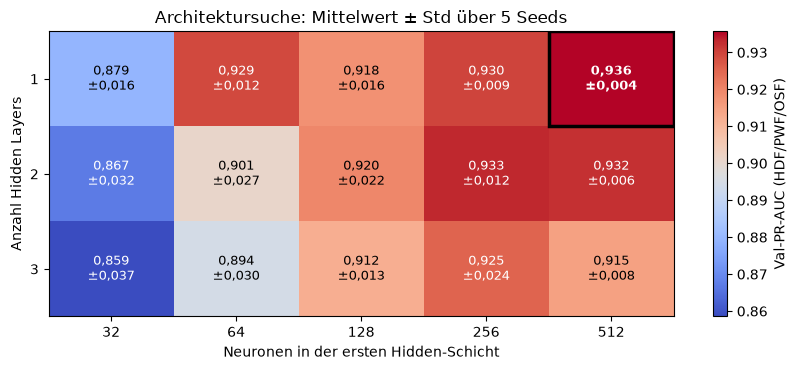

In [6]:
# Heatmap: Zeilen = Anzahl Hidden Layers, Spalten = Breite der ersten Schicht
mean_grid = search.pivot_table(index="depth", columns="width", values="pr_auc_mean_noTWF", aggfunc="mean")
std_grid = search.pivot_table(index="depth", columns="width", values="pr_auc_mean_noTWF", aggfunc="std")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
im = ax.imshow(mean_grid.values, cmap="coolwarm", aspect="auto")
ax.set_xticks(range(len(mean_grid.columns)), mean_grid.columns)
ax.set_yticks(range(len(mean_grid.index)), mean_grid.index)
ax.set_xlabel("Neuronen in der ersten Hidden-Schicht")
ax.set_ylabel("Anzahl Hidden Layers")
best_row, best_col = np.unravel_index(np.argmax(mean_grid.values), mean_grid.shape)
for i in range(mean_grid.shape[0]):
    for j in range(mean_grid.shape[1]):
        label = f"{mean_grid.values[i, j]:.3f}\n±{std_grid.values[i, j]:.3f}".replace(".", ",")
        norm_val = (mean_grid.values[i, j] - mean_grid.values.min()) / (mean_grid.values.max() - mean_grid.values.min())
        ax.text(j, i, label, ha="center", va="center", fontsize=9,
                color="white" if (norm_val < 0.2 or norm_val > 0.8) else "black",
                fontweight="bold" if (i, j) == (best_row, best_col) else "normal")
ax.add_patch(plt.Rectangle((best_col - 0.5, best_row - 0.5), 1, 1, fill=False, edgecolor="black", lw=2.5))
fig.colorbar(im, ax=ax, label="Val-PR-AUC (HDF/PWF/OSF)")
ax.set_title("Architektursuche: Mittelwert ± Std über 5 Seeds")
plt.tight_layout()
plt.savefig(figure_path("mlp", "mlp_architecture_search.png"), dpi=150, bbox_inches="tight")
plt.show()

## 4. Training mit Early Stopping

Kriterium: gemittelte Validierungs-PR-AUC über alle vier Labels.

In [7]:
model = MLPMultiLabel(input_dim=input_dim, n_labels=len(TARGET_COLUMNS))

model, history = train_classifier(
    model, train_loader, val_loader, device,
    epochs=150, lr=1e-3, pos_weight=pos_weight, patience=15,
)
print(f"Training beendet nach {len(history['train_loss'])} Epochen.")

Early Stopping nach Epoche 73 (keine Verbesserung seit 15 Epochen)
Training beendet nach 73 Epochen.


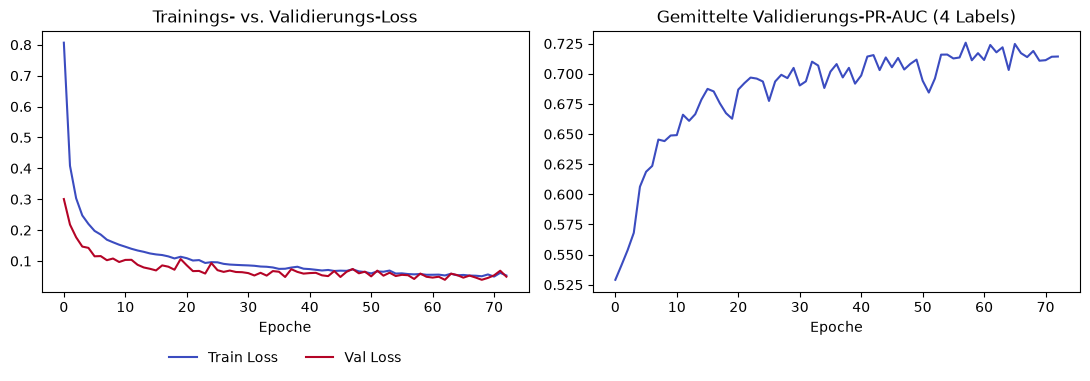

In [8]:
# Linke Grafik: Loss-Verlauf; rechte Grafik: gemittelte PR-AUC über alle 4 Labels je Epoche
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["train_loss"], label="Train Loss", color="#3b4cc0")
axes[0].plot(history["val_loss"], label="Val Loss", color="#b40426")
axes[0].set_title("Trainings- vs. Validierungs-Loss")
axes[0].set_xlabel("Epoche")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
axes[1].plot(history["val_pr_auc_mean"], color="#3b4cc0")
axes[1].set_title("Gemittelte Validierungs-PR-AUC (4 Labels)")
axes[1].set_xlabel("Epoche")
plt.tight_layout()
plt.savefig(figure_path("mlp", "mlp_learning_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

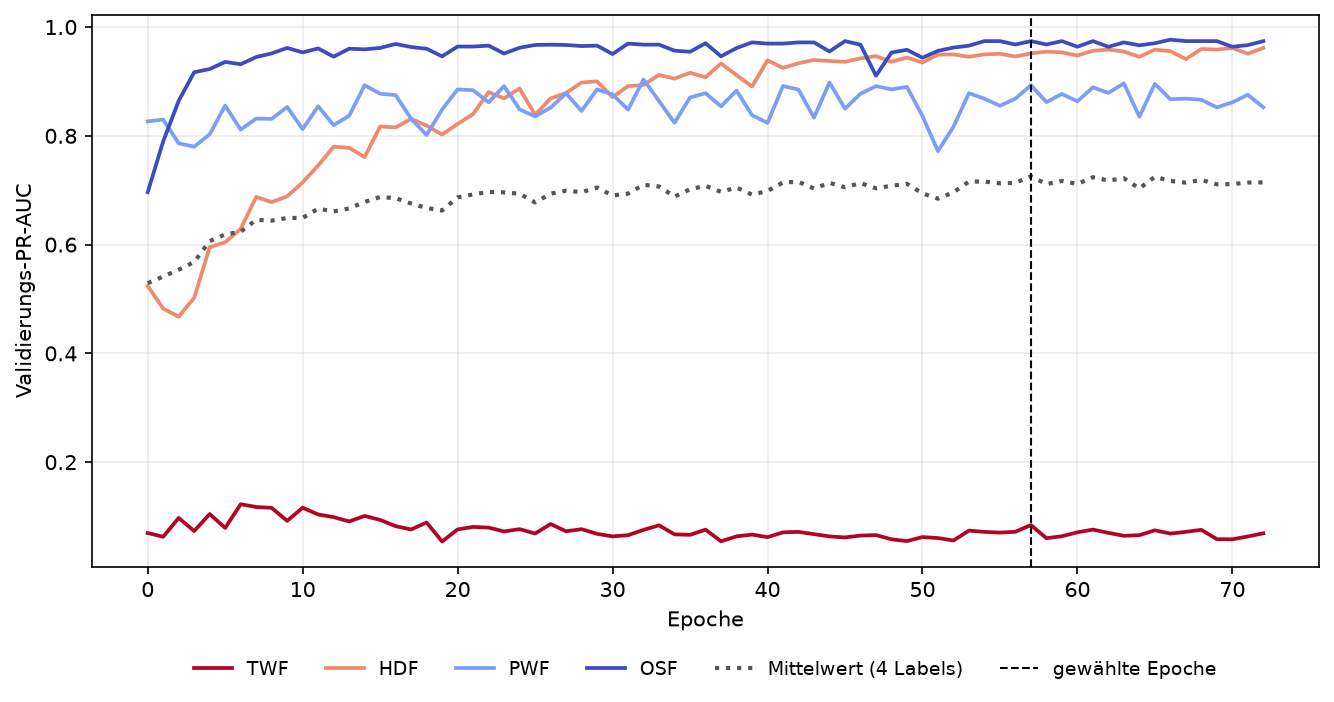

In [9]:
# Validierungs-PR-AUC je Label (Kurven der Einzel-Labels; Early Stopping nutzt nur den Mittelwert)
draw_label_learning_curves(history, TARGET_COLUMNS, figure_path("mlp", "mlp_learning_curves_per_label.png"))
from IPython.display import Image, display
display(Image(figure_path("mlp", "mlp_learning_curves_per_label.png")))

In [10]:
# Architekturdiagramm aus der gewählten Konfiguration zeichnen
draw_mlp_architecture(
    hidden_dims=HIDDEN_DIMS,
    input_labels=["type_M", "type_L", "type_H", "Temperature diff [K]", "Power [W]", "Tool wear [min]",
                  "Torque [Nm]", "Rotational speed [rpm]", "Process temperature [K]", "Air temperature [K]"],
    output_labels=TARGET_COLUMNS,
    path=figure_path("mlp", "mlp_architecture.png"),
)

## 5. Evaluation auf dem Testset (Standard-Schwelle 0,5)

In [11]:
# threshold=0.5 als Ausgangspunkt; die tatsächlich optimalen Schwellenwerte
# je Label werden erst in Notebook 04 bestimmt
result = evaluate_classifier(model, test_loader, device, threshold=0.5)
result["metrics"]

,threshold,precision,recall,f1,roc_auc,pr_auc,n_positive,tn,fp,fn,tp
label,,,,,,,,,,,
TWF,0.5,0.069767,0.428571,0.120000,0.919721,0.053811,7,1453,40,4,3
HDF,0.5,0.772727,1.000000,0.871795,0.999683,0.975573,17,1478,5,0,17
PWF,0.5,0.560000,1.000000,0.717949,0.998894,0.878455,14,1475,11,0,14
OSF,0.5,0.535714,1.000000,0.697674,0.999731,0.977632,15,1472,13,0,15


## 6. Modell + Wahrscheinlichkeiten speichern

Val-Wahrscheinlichkeiten werden für die Schwellenwert-Optimierung in Notebook 04 benötigt.

In [12]:
result["metrics"].to_csv(result_path("mlp", "mlp_multilabel_testset_metrics.csv"))
torch.save(model.state_dict(), "../models/mlp_multilabel.pt")

# Val- und Test-Wahrscheinlichkeiten separat sichern (Val für die
# Schwellenwert-Suche, Test für die spätere finale Auswertung)
val_result = evaluate_classifier(model, val_loader, device, threshold=0.5)
np.savez("../data/processed/mlp_val_probs.npz", y_true=val_result["y_true"], y_prob=val_result["y_prob"])
np.savez("../data/processed/mlp_test_probs.npz", y_true=result["y_true"], y_prob=result["y_prob"])
print("Modell + Val-/Test-Wahrscheinlichkeiten gespeichert.")

Modell + Val-/Test-Wahrscheinlichkeiten gespeichert.
